# Supervised Learning & Model Engineering - Group project
# STEP 4: Class imbalance - business cost, threshold, class weights, SMOTE

**Dataset:** Adult / Census Income (OpenML, `name="adult"`, `version=2`)
**Group:** Clément, Eliott Monneraie, Lucas Stefani (lead for this step: Clément, reviewed by all)
**Course reference:** Session 6 (imbalanced classification: threshold tuning, class weights, SMOTE, business cost)
**Code:** `src/imbalance.py` (comparison of the remedies), `src/evaluate.py` (business cost, threshold choice), `src/models.py` (class-weight and SMOTE options). This notebook calls the code, shows the results and explains our choices.

### How to read this notebook
Same labels as before: **What we see**, **What we decide**, **What could invalidate it**, **Note for STEP X**, **Limitation**.

### The rule of this step
Development set only, same 5 folds and same grader as STEP 3. Every threshold is chosen on **out-of-fold** predictions. The test set is not touched (STEP 6).

### How to run
From the project root, after `python -m src.data`. Runtime: about two minutes (SMOTE is the slowest).

In [1]:
# ===================== Setup =====================
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src.data import load_config, load_splits, get_cv
from src.evaluate import threshold_table, best_threshold, compute_metrics
from src.imbalance import run_remedies, remedy_summary, sensitivity_table, cross_validated_threshold
from src.tracking import setup_mlflow, log_cv_run

warnings.filterwarnings("ignore")
cfg = load_config()
ICFG = cfg["imbalance"]
X_COST, FP_COST = ICFG["cost_fn"], ICFG["cost_fp"]
FIG_DIR = cfg["paths"]["figures_dir"]
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")

def savefig(name: str) -> str:
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved: {path}")
    return path

X_dev, _, y_dev, _ = load_splits(cfg)          # the test set is not used in STEP 4
cv = get_cv(cfg)
print(f"Development set: {len(y_dev)} people, {int(y_dev.sum())} earn >50K ({y_dev.mean():.1%})")

Development set: 39032 people, 9345 earn >50K (23.9%)


---
# Part A - The problem and the course's remedies

**The problem (end of STEP 3).** At the default threshold 0.5, the baseline contacts 7,680 people and **misses 3,785 of the 9,345 wealthy prospects (40%)**. Only 24% of people earn >50K: the model sees three times more <=50K examples, so it says ">50K" only when it is very sure, and 0.5 is a default, not a business choice.

**The three remedies of Session 6, tested in this order** (*"Baseline -> Threshold -> Class weights -> SMOTE"*):

| Remedy | What changes | Retrains the model? | Course |
|---|---|---|---|
| **Threshold tuning** | Only the cut-off: "contact if $\hat p \ge t$" with $t$ chosen for the business | No | S6: *"changes decisions"* |
| **Class weights** (`class_weight="balanced"`) | Errors on >50K people weigh about 3.2 times more in the training loss ($n_{neg}/n_{pos}$) | Yes | S6: *"changes learning"* |
| **SMOTE** | Synthetic >50K people are created between real neighbours, **in the training folds only** | Yes | S6: *"evaluated after less invasive remedies and only inside training folds"* |

**What we decide.** We compare the three on the same folds with the same grader, and **keep the least invasive remedy unless another one clearly lowers the business cost** (Session 6 hierarchy).

---
# Part B - The business cost (decision 27)

Session 6 lists the **business cost** of false positives and false negatives as the metric to choose an operating point. For our bank:
- a **false positive** = a useless call;
- a **false negative** = a wealthy prospect never contacted.

$$\text{cost} = X \times \text{(wealthy prospects missed)} + 1 \times \text{(useless calls)}$$

**How we set $X$: rough business numbers, stated as assumptions.**

| Element | Assumption | Value |
|---|---|---|
| Time spent on a useless call (preparation, call, CRM) | about 30 minutes at ~EUR 100 per hour loaded cost | **EUR 50** |
| Assets entrusted by a new wealthy client | EUR 300,000 | |
| Annual fees (discretionary management / advisory) | about 1% | EUR 3,000 per year |
| Share of contacted wealthy prospects who sign | 10% | |
| Expected value of contacting a wealthy prospect | 10% x EUR 3,000 | **EUR 300** |
| **Ratio** | EUR 300 / EUR 50 | **about 6, rounded down to $X = 5$** |

**Why rounding down is conservative.** We only count the first year of fees; a client usually stays several years, so the true ratio is probably higher than 6.

**Limitation.** These numbers are illustrative assumptions, not data from a bank. That is why Part E checks the conclusions for $X = 2, 3, 5, 10$. If advisors had a fixed number of calls per week, that capacity would decide the threshold instead.

---
# Part C - How the threshold is chosen

For a given $X$, the threshold is not chosen by us: it is **computed**. On the out-of-fold predictions (each person predicted by a model that never saw them), we try every threshold from 0.01 to 0.99, count the wealthy prospects missed and the useless calls, and keep the threshold with the **lowest total cost**.

In [2]:
# ===================== C.1 Run the three remedies (same 5 folds) =====================
results = run_remedies(cfg, X_dev, y_dev, cv)
oof_base = results["threshold_only"][1]           # baseline logistic regression, out-of-fold

table = threshold_table(y_dev, oof_base, X_COST, FP_COST)
t_best = best_threshold(y_dev, oof_base, X_COST, FP_COST)
show = table[table["threshold"].isin([0.50, 0.40, 0.30, 0.25, 0.20, t_best, 0.15, 0.10, 0.05])]
display(show[["threshold", "calls", "tp", "fn", "fp", "precision", "recall", "cost"]]
        .rename(columns={"tp": "wealthy found", "fn": "wealthy missed", "fp": "useless calls"})
        .style.format({"precision": "{:.3f}", "recall": "{:.3f}", "cost": "{:,.0f}", "threshold": "{:.2f}"}))
print(f"Threshold with the lowest cost (X = {X_COST}): {t_best:.2f}")

,threshold,calls,wealthy found,wealthy missed,useless calls,precision,recall,cost
4,0.05,23579,9146,199,14433,0.388,0.979,"15,428"
9,0.10,19901,8887,458,11014,0.447,0.951,"13,304"
14,0.15,17498,8582,763,8916,0.490,0.918,"12,731"
16,0.17,16692,8456,889,8236,0.507,0.905,"12,681"
19,0.20,15466,8233,1112,7233,0.532,0.881,"12,793"
24,0.25,13831,7842,1503,5989,0.567,0.839,"13,504"
29,0.30,12224,7362,1983,4862,0.602,0.788,"14,777"
39,0.40,9741,6470,2875,3271,0.664,0.692,"17,646"
49,0.50,7680,5560,3785,2120,0.724,0.595,"21,045"


Threshold with the lowest cost (X = 5): 0.17


Figure saved: reports/figures/14_cost_by_threshold.png


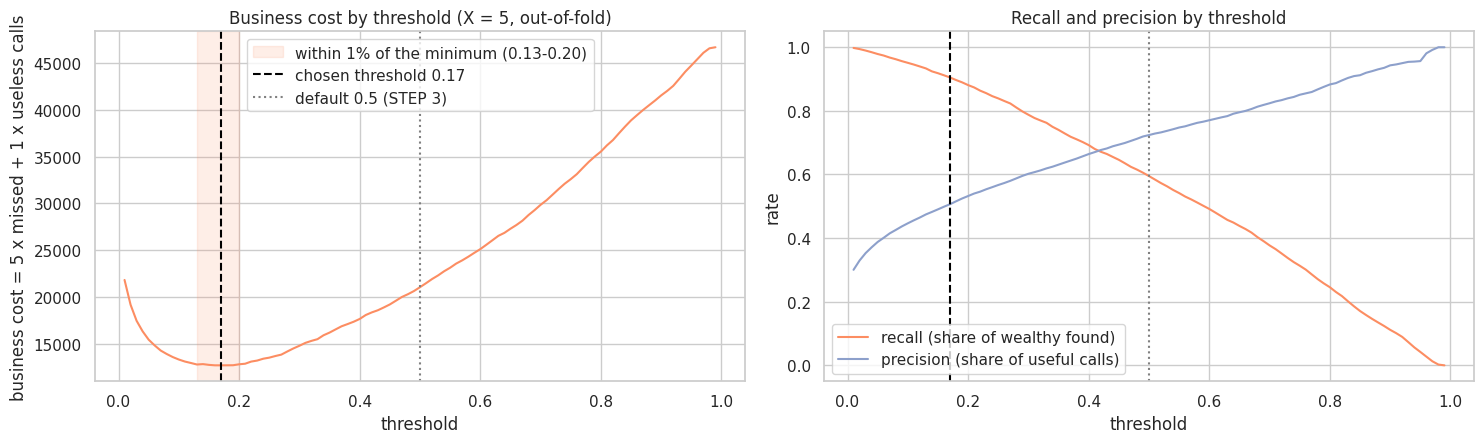

In [3]:
# ===================== C.2 Cost curve =====================
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
min_cost = table["cost"].min()
axes[0].plot(table["threshold"], table["cost"], color="#fc8d62")
near = table[table["cost"] <= 1.01 * min_cost]
axes[0].axvspan(near["threshold"].min(), near["threshold"].max(), color="#fc8d62", alpha=0.15,
                label=f"within 1% of the minimum ({near['threshold'].min():.2f}-{near['threshold'].max():.2f})")
axes[0].axvline(t_best, color="black", ls="--", label=f"chosen threshold {t_best:.2f}")
axes[0].axvline(0.5, color="grey", ls=":", label="default 0.5 (STEP 3)")
axes[0].set(xlabel="threshold", ylabel=f"business cost = {X_COST} x missed + 1 x useless calls",
            title=f"Business cost by threshold (X = {X_COST}, out-of-fold)"); axes[0].legend()

axes[1].plot(table["threshold"], table["recall"], label="recall (share of wealthy found)", color="#fc8d62")
axes[1].plot(table["threshold"], table["precision"], label="precision (share of useful calls)", color="#8da0cb")
axes[1].axvline(t_best, color="black", ls="--"); axes[1].axvline(0.5, color="grey", ls=":")
axes[1].set(xlabel="threshold", ylabel="rate", title="Recall and precision by threshold"); axes[1].legend()
fig_cost = savefig("14_cost_by_threshold")
plt.show()

**What we see.**
- Starting from 0.5 and lowering the threshold, the **cost first falls** (each wealthy prospect found saves 5 units) and **then rises again** (useless calls pile up faster than new wealthy prospects are found). The minimum is at **0.17**.
- The bottom of the curve is **flat**: every threshold in the shaded band is within 1% of the minimum. The exact value inside that band hardly matters.
- On the right: lowering the threshold raises recall and lowers precision, exactly the trade-off of Session 6.

**What we decide.** With $X = 5$ we contact every prospect with at least a **17% probability** of earning >50K.

---
# Part D - Which remedy? Threshold vs class weights vs SMOTE

,pr_auc,pr_auc_std,roc_auc,log_loss,threshold,calls,found,missed,useless_calls,precision,recall,fold_cost_mean,fold_cost_std,fold_best_thresholds
remedy,,,,,,,,,,,,,,
threshold_only,0.745,0.012,0.901,0.328,0.17,16692,8456,889,8236,0.507,0.905,"2,536",80,"0.12, 0.18, 0.19, 0.18, 0.19"
class_weight,0.743,0.012,0.901,0.403,0.38,16959,8515,830,8444,0.502,0.911,"2,519",79,"0.31, 0.38, 0.34, 0.42, 0.42"
smote,0.744,0.011,0.901,0.399,0.37,16797,8471,874,8326,0.504,0.906,"2,539",78,"0.33, 0.36, 0.39, 0.42, 0.34"


Figure saved: reports/figures/15_remedy_comparison.png


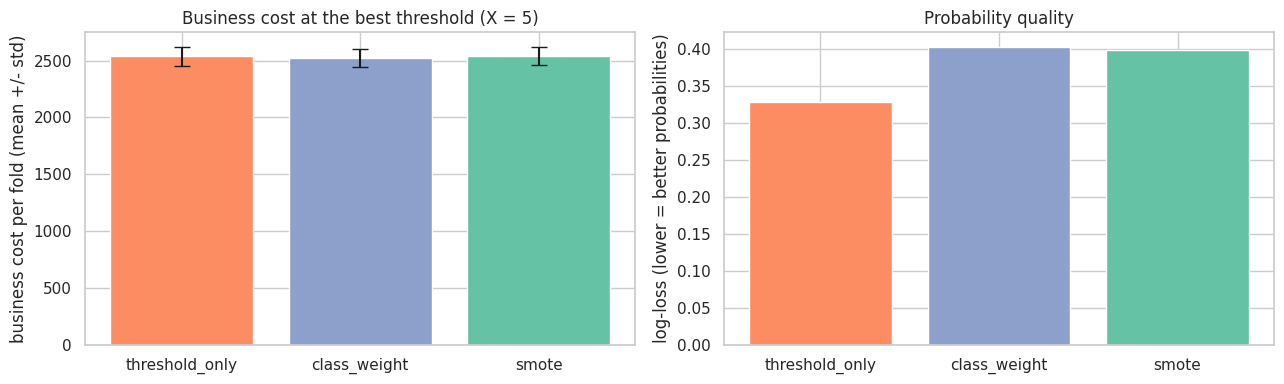

In [4]:
# ===================== D.1 Comparison at X = 5 =====================
summary = remedy_summary(y_dev, results, cv, X_dev, X_COST, FP_COST)
cols = ["pr_auc", "pr_auc_std", "roc_auc", "log_loss", "threshold", "calls", "found", "missed",
        "useless_calls", "precision", "recall", "fold_cost_mean", "fold_cost_std", "fold_best_thresholds"]
display(summary[cols].style.format({c: "{:.3f}" for c in ["pr_auc", "pr_auc_std", "roc_auc", "log_loss",
                                                          "precision", "recall"]}
                                   | {"threshold": "{:.2f}", "fold_cost_mean": "{:,.0f}", "fold_cost_std": "{:,.0f}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = list(summary.index)
axes[0].bar(names, summary["fold_cost_mean"], yerr=summary["fold_cost_std"], capsize=6,
            color=["#fc8d62", "#8da0cb", "#66c2a5"])
axes[0].set(ylabel="business cost per fold (mean +/- std)", title=f"Business cost at the best threshold (X = {X_COST})")
axes[1].bar(names, summary["log_loss"], color=["#fc8d62", "#8da0cb", "#66c2a5"])
axes[1].set(ylabel="log-loss (lower = better probabilities)", title="Probability quality")
fig_remedies = savefig("15_remedy_comparison")
plt.show()

**What we see.**
- **PR-AUC and ROC-AUC are the same for the three remedies** (0.743 to 0.745, 0.901): none of them ranks the prospects better. This is what Session 6 says about threshold tuning, and here class weights and SMOTE do not improve the ranking either.
- **The business cost is the same**: about 2,520 to 2,540 per fold, and the differences (about 20) are four times smaller than the variation between folds (about 80). At their own best threshold, the three remedies find about 90% of the wealthy prospects with about 50% useful calls.
- **The log-loss gets worse with class weights (0.403) and SMOTE (0.399)** compared with 0.328. Both push the predicted probabilities upwards: a person with a true 20% chance gets a predicted probability closer to 40%. That is also why their best thresholds are higher (0.38 and 0.37 instead of 0.17): they reach the same decisions with distorted probabilities.
- The best threshold fold by fold stays between 0.12 and 0.19 for the threshold-only remedy: the choice is stable.

**What we decide: threshold tuning only.**
1. Same business result as the two other remedies.
2. Least invasive (Session 6 hierarchy): no retraining, no synthetic people.
3. **It keeps the probabilities honest.** A probability of 17% still means about 17%, which matters for STEP 7 (calibration) and for the bank, which may want to rank and explain prospects by probability.

**Limitation (SMOTE).** SMOTE runs after the one-hot encoding, so it interpolates between 0/1 columns and creates people who are, for example, "0.4 married". Session 6 warns that synthetic observations *"may be unrealistic"*. It is one more reason not to keep it.

**What could invalidate it.** If a remedy lowered the cost by more than the fold-to-fold variation for another model (STEP 5), we would reconsider it for that model.

---
# Part E - Robustness of the business assumption: X = 2, 3, 5, 10
The data cannot tell us the right $X$: every $X$ has its own best threshold. What the table below gives is **the price of each option**, so that the choice can be argued in business terms.

Reference STEP 3 (t = 0.50): 7,680 calls, 5,560 wealthy found (59.5%), 3,785 missed


,threshold,calls,share_called,found,missed,recall,precision,extra_calls,extra_found,calls_per_extra_found
X,,,,,,,,,,
2,0.33,11507,29.5%,7125,2220,76.2%,61.9%,nan,nan,nan
3,0.21,15114,38.7%,8164,1181,87.4%,54.0%,"3,607","1,039",3.5
5,0.17,16692,42.8%,8456,889,90.5%,50.7%,"1,578",292,5.4
10,0.10,19901,51.0%,8887,458,95.1%,44.7%,"3,209",431,7.4


,cost threshold_only,cost class_weight,cost smote
X,,,
2,"1,764 +/- 61","1,765 +/- 40","1,767 +/- 45"
3,"2,099 +/- 50","2,102 +/- 49","2,091 +/- 46"
5,"2,536 +/- 80","2,519 +/- 79","2,539 +/- 78"
10,"3,119 +/- 53","3,097 +/- 92","3,131 +/- 92"


Figure saved: reports/figures/16_cost_ratio_sensitivity.png


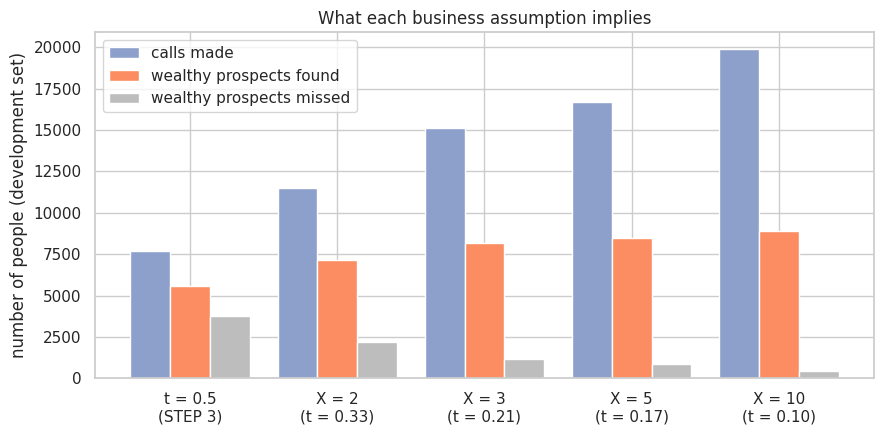

In [5]:
# ===================== E.1 Sensitivity table =====================
sens = sensitivity_table(y_dev, oof_base, ICFG["cost_fn_sensitivity"], FP_COST)
base_point = threshold_table(y_dev, oof_base, X_COST, FP_COST, thresholds=np.array([0.5])).iloc[0]
print(f"Reference STEP 3 (t = 0.50): {int(base_point['calls']):,} calls, {int(base_point['tp']):,} wealthy found "
      f"({base_point['recall']:.1%}), {int(base_point['fn']):,} missed")
display(sens.style.format({"threshold": "{:.2f}", "share_called": "{:.1%}", "recall": "{:.1%}", "precision": "{:.1%}",
                           "extra_calls": "{:,.0f}", "extra_found": "{:,.0f}", "calls_per_extra_found": "{:.1f}"}))

# Same conclusion on the remedies for every X?
rows = []
for x in ICFG["cost_fn_sensitivity"]:
    s = remedy_summary(y_dev, results, cv, X_dev, x, FP_COST)
    rows.append({"X": x, **{f"cost {r}": f"{s.loc[r, 'fold_cost_mean']:,.0f} +/- {s.loc[r, 'fold_cost_std']:,.0f}" for r in s.index}})
display(pd.DataFrame(rows).set_index("X"))

fig, ax = plt.subplots(figsize=(9, 4.5))
labels = ["t = 0.5\n(STEP 3)"] + [f"X = {x}\n(t = {sens.loc[x, 'threshold']:.2f})" for x in sens.index]
calls = [base_point["calls"]] + list(sens["calls"]); found = [base_point["tp"]] + list(sens["found"])
missed = [base_point["fn"]] + list(sens["missed"])
pos = np.arange(len(labels)); w = 0.27
ax.bar(pos - w, calls, w, label="calls made", color="#8da0cb")
ax.bar(pos, found, w, label="wealthy prospects found", color="#fc8d62")
ax.bar(pos + w, missed, w, label="wealthy prospects missed", color="#bdbdbd")
ax.set_xticks(pos); ax.set_xticklabels(labels); ax.set_ylabel("number of people (development set)")
ax.set_title("What each business assumption implies"); ax.legend()
fig_sens = savefig("16_cost_ratio_sensitivity")
plt.show()

**What we see.**
- The bigger $X$, the lower the threshold and the more people are called: from 29% of prospects ($X = 2$) to 51% ($X = 10$).
- **Returns diminish.** Going from $X = 2$ to $X = 3$ costs **3.5 extra calls per extra wealthy prospect found**; from 3 to 5, **5.4**; from 5 to 10, **7.4**.
- **The remedy conclusion is the same for every $X$**: the three remedies always have the same cost within the fold-to-fold variation.

**What we decide: $X = 5$, threshold 0.17.**
- It is the value our business assumptions support (expected value about EUR 300 vs EUR 50 per call, ratio about 6).
- The step from 3 to 5 costs 5.4 calls per extra wealthy client, below that ratio: worth it.
- The step from 5 to 10 costs 7.4 calls per extra wealthy client, above the ratio, and means calling half of all prospects: not justified by our assumptions.

**What could invalidate it.** Different business numbers (for example, a higher signing rate would raise $X$) or a fixed advisor capacity, which would set the number of calls directly.

---
# Part F - What changes for the bank (development set, out-of-fold)

In [6]:
# ===================== F.1 Before / after =====================
after = threshold_table(y_dev, oof_base, X_COST, FP_COST, thresholds=np.array([t_best])).iloc[0]
comp = pd.DataFrame({
    "STEP 3 (t = 0.50)": base_point, f"STEP 4 (t = {t_best:.2f}, X = {X_COST})": after,
}).T[["calls", "tp", "fn", "fp", "precision", "recall", "cost"]]
comp["share_called"] = comp["calls"] / len(y_dev)
display(comp.rename(columns={"tp": "wealthy found", "fn": "wealthy missed", "fp": "useless calls"})
        .style.format({"precision": "{:.1%}", "recall": "{:.1%}", "share_called": "{:.1%}", "cost": "{:,.0f}",
                       "calls": "{:,.0f}", "wealthy found": "{:,.0f}", "wealthy missed": "{:,.0f}", "useless calls": "{:,.0f}"}))

,calls,wealthy found,wealthy missed,useless calls,precision,recall,cost,share_called
STEP 3 (t = 0.50),"7,680","5,560","3,785","2,120",72.4%,59.5%,"21,045",19.7%
"STEP 4 (t = 0.17, X = 5)","16,692","8,456",889,"8,236",50.7%,90.5%,"12,681",42.8%


**What we see.**
- **Wealthy prospects found: 60% -> 90%** (5,560 -> 8,456). Missed: 3,785 -> 889.
- Price: **calls go from 7,680 to 16,692** (20% -> 43% of prospects), and **precision falls from 72% to 51%**: one call in two is useful instead of almost three in four.
- **Business cost: 21,045 -> 12,681 (-40%)** under our assumption $X = 5$.
- The ranking itself (PR-AUC 0.745) has not changed: only the operating point moved, as Session 6 predicts.

**Limitation.** The threshold is chosen and evaluated on the same out-of-fold predictions, so these numbers are slightly optimistic. Part F.2 measures by how much.

## F.2 Is the threshold result too optimistic? An honest check

**Why we do this.** To find 0.17 we tried 99 thresholds and kept the one with the lowest cost, then reported the cost **on the same predictions**. It is the same trap as a **backtest in finance**: test 99 strategies on 2020-2024, keep the best, and announce its return measured on 2020-2024. Part of that return is luck on that particular period, so the real performance on new data is usually a bit lower. Our 0.17 may likewise have been "lucky" on these particular people.

**How we fix it: the logic of cross-validation applied to the threshold** (an out-of-sample backtest). For each of the 5 folds:
1. we choose the best threshold using only the **other 4 folds**;
2. we measure the cost on **this fold**, which played no part in the choice.

The sum over the 5 folds is an **honest** cost: every person is judged with a threshold chosen without them. We compare it with the in-sample cost (threshold 0.17 chosen on everyone, measured on the same people).

In [7]:
# ===================== F.2 Cross-validated threshold =====================
honest = cross_validated_threshold(y_dev, oof_base, cv, X_dev, X_COST, FP_COST)
display(honest.style.format({"threshold_chosen_without_fold": "{:.2f}", "threshold_all_data": "{:.2f}",
                             "cost_honest": "{:,.0f}", "cost_in_sample": "{:,.0f}",
                             "recall_honest": "{:.1%}", "precision_honest": "{:.1%}"}))
tot_h, tot_i = honest["cost_honest"].sum(), honest["cost_in_sample"].sum()
print(f"Total cost, honest (threshold chosen without the fold): {tot_h:,.0f}")
print(f"Total cost, in-sample (0.17 chosen on everyone)       : {tot_i:,.0f}")
print(f"Optimism of the in-sample number: {(tot_h - tot_i) / tot_i:+.1%}")
print(f"Honest recall {honest['recall_honest'].mean():.1%}, honest precision {honest['precision_honest'].mean():.1%}")

,threshold_chosen_without_fold,cost_honest,recall_honest,precision_honest,threshold_all_data,cost_in_sample
fold,,,,,,
1,0.18,"2,683",88.1%,51.2%,0.17,"2,652"
2,0.19,"2,579",88.8%,52.0%,0.17,"2,560"
3,0.16,"2,510",91.7%,49.7%,0.17,"2,495"
4,0.17,"2,538",90.4%,50.8%,0.17,"2,538"
5,0.16,"2,442",92.0%,50.4%,0.17,"2,436"


Total cost, honest (threshold chosen without the fold): 12,752
Total cost, in-sample (0.17 chosen on everyone)       : 12,681
Optimism of the in-sample number: +0.6%
Honest recall 90.2%, honest precision 50.8%


**What we see.**
- The threshold chosen without each fold is always **between 0.16 and 0.19**: the choice does not depend on which people are used.
- The honest total cost is **12,752**, versus **12,681** in-sample: the in-sample number was optimistic by only **about 0.6%**, well inside the fold-to-fold variation.
- Honest recall **90.2%** and precision **50.8%**, versus 90.5% and 50.7% in-sample: practically identical.

**What we decide.** The STEP 4 result is not an artefact of the threshold search: we keep the threshold procedure as it is (decision 32). The final confirmation remains the single evaluation on the test set in STEP 6.

---
# Part G - MLflow: one run per remedy

In [8]:
# ===================== G.1 Log the three remedies =====================
import mlflow
setup_mlflow(cfg)
for name, (per_fold, _) in results.items():
    row = summary.loc[name]
    run_id = log_cv_run(
        f"step4_logistic_{name}",
        {"remedy": name, **{f"model_{k}": v for k, v in cfg["models"]["logistic"].items()},
         "cost_fn": X_COST, "cost_fp": FP_COST, "seed": cfg["seed"]},
        per_fold, tags={"step": "4", "model": "logistic_regression", "family": "linear"},
        figures=[fig_cost, fig_remedies, fig_sens] if name == "threshold_only" else None)
    with mlflow.start_run(run_id=run_id):
        mlflow.log_metrics({"chosen_threshold": row["threshold"], "business_cost": row["cost"],
                            "recall_at_threshold": row["recall"], "precision_at_threshold": row["precision"]})

runs = mlflow.search_runs(experiment_names=[cfg["tracking"]["experiment_name"]])
display(runs[["tags.mlflow.runName", "params.remedy", "metrics.cv_pr_auc_mean", "metrics.cv_log_loss_mean",
              "metrics.chosen_threshold", "metrics.business_cost"]].round(3))

2026/10/18 11:56:40 INFO mlflow.tracking.fluent: Experiment with name 'adult-income' does not exist. Creating a new experiment.


,tags.mlflow.runName,params.remedy,metrics.cv_pr_auc_mean,metrics.cv_log_loss_mean,metrics.chosen_threshold,metrics.business_cost
0,step4_logistic_smote,smote,0.744,0.399,0.37,12696.0
1,step4_logistic_class_weight,class_weight,0.743,0.403,0.38,12594.0
2,step4_logistic_threshold_only,threshold_only,0.745,0.328,0.17,12681.0


---
# Part H - Decisions log for STEP 4 (copied into DECISIONS.md)

| # | Decision | Why | What could invalidate it | Where |
|---|---|---|---|---|
| 27 | Business cost = 5 x missed wealthy prospects + 1 x useless calls ($X = 5$) | Useless call ~ EUR 50 (30 min of advisor time); contacted wealthy prospect ~ EUR 300 expected value (10% x 1% fees on EUR 300k, first year only); ratio ~ 6 rounded down | Different business numbers; fixed advisor capacity | `config.yaml` (`imbalance`) |
| 28 | The threshold minimises the business cost on out-of-fold predictions: **0.17** for the baseline | Course rule: no universal threshold, chosen on development data, never on the test set (S6); flat minimum (0.13-0.20 within 1% of the lowest cost) and stable per fold (0.12-0.19) | - | `best_threshold`, `src/imbalance.py` |
| 29 | Remedy kept: **threshold tuning only** (no class weights, no SMOTE) | Same PR-AUC and same business cost (differences ~20, fold std ~80); class weights and SMOTE worsen log-loss (0.328 -> 0.40) and SMOTE creates unrealistic one-hot rows; least invasive (S6 hierarchy) | Another model where a remedy clearly lowers the cost | `config.yaml` (`imbalance.remedy`) |
| 30 | Sensitivity $X$ = 2, 3, 5, 10: same remedy conclusion for every $X$; marginal price 3.5 / 5.4 / 7.4 calls per extra wealthy client | Shows the decision does not hinge on the exact assumption | - | notebook 04, Part E |
| 31 | Result (development, out-of-fold): wealthy found 60% -> 90%, calls 20% -> 43% of prospects, precision 72% -> 51%, business cost -40%; PR-AUC unchanged (0.745) | Threshold changes the operating point, not the ranking (S6) | Test-set confirmation (STEP 6) | notebook 04, Part F |
| 32 | Honest check of the threshold choice: threshold chosen on 4 folds, cost measured on the 5th (cross-validated threshold) | Choosing and measuring on the same predictions is optimistic (like an in-sample backtest); measured optimism only ~0.6% (12,752 vs 12,681), thresholds 0.16-0.19 | - | `cross_validated_threshold`, notebook 04 F.2 |

**Notes for the next steps.**
- **STEP 5:** Random Forest and LightGBM are tuned **without** class weights / `scale_pos_weight`, and their threshold is chosen with the same business cost. Optionally, `scale_pos_weight` (S6) can be checked for LightGBM with the same rule.
- **STEP 6:** the threshold is recomputed for the final model on its own out-of-fold predictions (the 0.17 belongs to the baseline), then applied once to the test set.
- **STEP 7:** keeping the threshold rather than class weights preserves the probabilities, so calibration starts from honest probabilities.
- **STEP 9:** lowering the threshold to 0.17 doubles the number of people contacted; check the selection rate by sex and race on the final model.